# CSCN8010 Lab 2: Diabetes Progression Modeling

**Objective.** Explore baseline measurements from scikit-learn's diabetes toy dataset and compare regression models that estimate the quantitative disease-progression measure one year after baseline. This is a modeling exercise, not a clinical diagnostic tool.

The notebook follows a train/validation/test workflow: 75% / 10% / 15%. Models are fitted on training data, selected using validation results, and evaluated on the test set only after selection.

## 1. Dataset and problem framing

The official scikit-learn description says the dataset contains ten baseline variables (age, sex, body mass index, average blood pressure, and six serum measurements) for 442 diabetes patients. The response is a **quantitative measure of disease progression one year after baseline**. Therefore the primary task is regression, not predicting whether a person has diabetes.

The features in scikit-learn's version are scaled/centered. In particular, `bmi` is not BMI in kg/m²; a value such as 0.05 is a standardized feature value. The dataset is a small educational sample and is not representative enough to validate a real-world clinical screening system.

We report R-squared, MAE, and MAPE for continuous-target regressors. R-squared describes variance explained relative to the mean baseline and can be negative on unseen data. MAE is the average absolute target-unit error. MAPE expresses absolute error relative to the true target; it is interpretable here because the supplied target values are nonzero, but percentage errors can be unstable near zero. As emphasized in the classification, KNN, and logistic-regression workshops, metric choice must match the prediction task and the consequences of false positives and false negatives.

Logistic regression is a **classifier**, so it cannot directly predict the continuous progression target or be meaningfully scored with R-squared/MAE/MAPE. To include the requested logistic models without misrepresenting their output, we separately define a high-progression class using the training-set median and report classification metrics. This binary experiment is supplementary and its threshold is not a clinical cutoff.

In [1]:
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

from src.analysis import (
    BMI, TARGET, load_data, split_data,
    make_univariate_models, make_multivariate_models, make_logistic_models,
    evaluate_regressors, evaluate_logistic_models,
    select_best_by_validation_mae, test_regression_model, test_logistic_model,
    polynomial_equation, polynomial_parameter_count, describe_parameterization,
    bmi_prediction,
)

pd.set_option('display.precision', 3)
plt.style.use('seaborn-v0_8-whitegrid')

## 2. Get and inspect the data

The checked-in CSV is the dataframe returned by `sklearn.datasets.load_diabetes(as_frame=True)`. It preserves the ten features and the numeric target. Review the data shape, column types, descriptive statistics, and completeness before fitting models.

In [2]:
data = load_data()
print(f'Shape: {data.shape}')
display(data.head())
display(data.dtypes.rename('dtype').to_frame())
display(data.describe().T)
print(f'Missing cells: {int(data.isna().sum().sum())}')
print(f'Duplicate rows: {int(data.duplicated().sum())}')
print(f'Target range: {data[TARGET].min():.1f} to {data[TARGET].max():.1f}')

Shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038,0.051,0.062,0.022,-0.044,-0.035,-0.043,-0.003,0.020,-0.018,151.0
1,-0.002,-0.045,-0.051,-0.026,-0.008,-0.019,0.074,-0.039,-0.068,-0.092,75.0
2,0.085,0.051,0.044,-0.006,-0.046,-0.034,-0.032,-0.003,0.003,-0.026,141.0
3,-0.089,-0.045,-0.012,-0.037,0.012,0.025,-0.036,0.034,0.023,-0.009,206.0
4,0.005,-0.045,-0.036,0.022,0.004,0.016,0.008,-0.003,-0.032,-0.047,135.0


,dtype
age,float64
sex,float64
bmi,float64
bp,float64
s1,float64
s2,float64
s3,float64
s4,float64
s5,float64
s6,float64


,count,mean,std,min,25%,50%,75%,max
age,442.0,-7.284e-18,0.048,-0.107,-0.037,0.005,0.038,0.111
sex,442.0,2.349e-17,0.048,-0.045,-0.045,-0.045,0.051,0.051
bmi,442.0,-2.087e-16,0.048,-0.090,-0.034,-0.007,0.031,0.171
bp,442.0,-4.572e-17,0.048,-0.112,-0.037,-0.006,0.036,0.132
s1,442.0,-9.294e-18,0.048,-0.127,-0.034,-0.004,0.028,0.154
s2,442.0,4.421e-17,0.048,-0.116,-0.030,-0.004,0.030,0.199
s3,442.0,2.135e-18,0.048,-0.102,-0.035,-0.007,0.029,0.181
s4,442.0,2.914e-17,0.048,-0.076,-0.039,-0.003,0.034,0.185
s5,442.0,9.143e-17,0.048,-0.126,-0.033,-0.002,0.032,0.134
s6,442.0,1.432e-17,0.048,-0.138,-0.033,-0.001,0.028,0.136


Missing cells: 0
Duplicate rows: 0
Target range: 25.0 to 346.0


### EDA: distributions, relationships, and correlation

Histograms show feature and target distributions; scatter plots show the marginal association between each baseline feature and progression; the correlation matrix highlights pairwise linear associations. These views are descriptive and do not establish causal relationships.

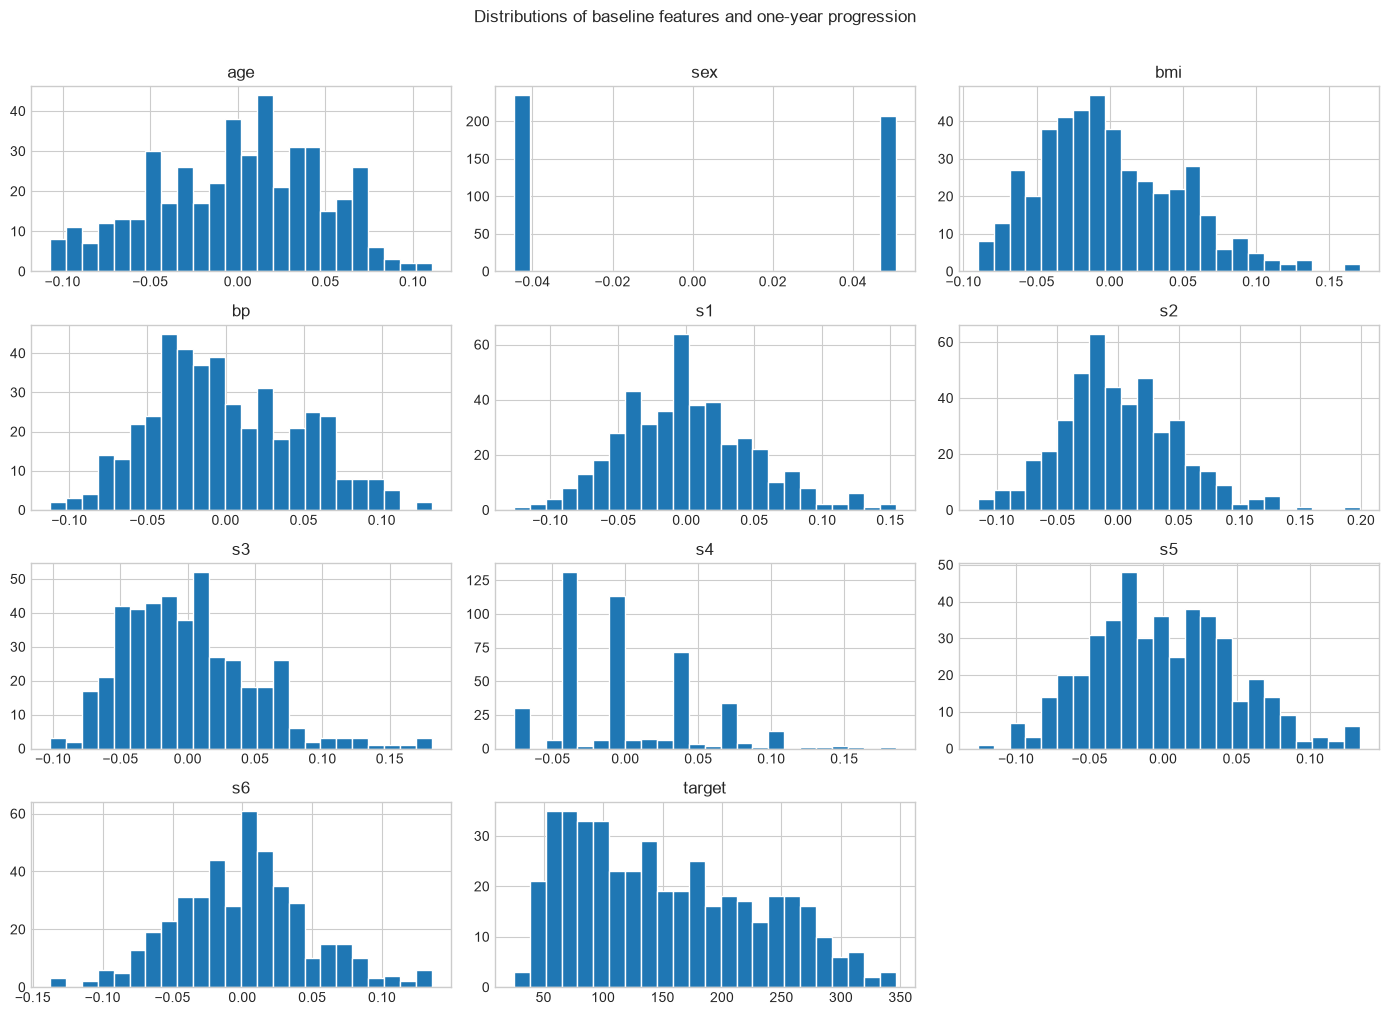

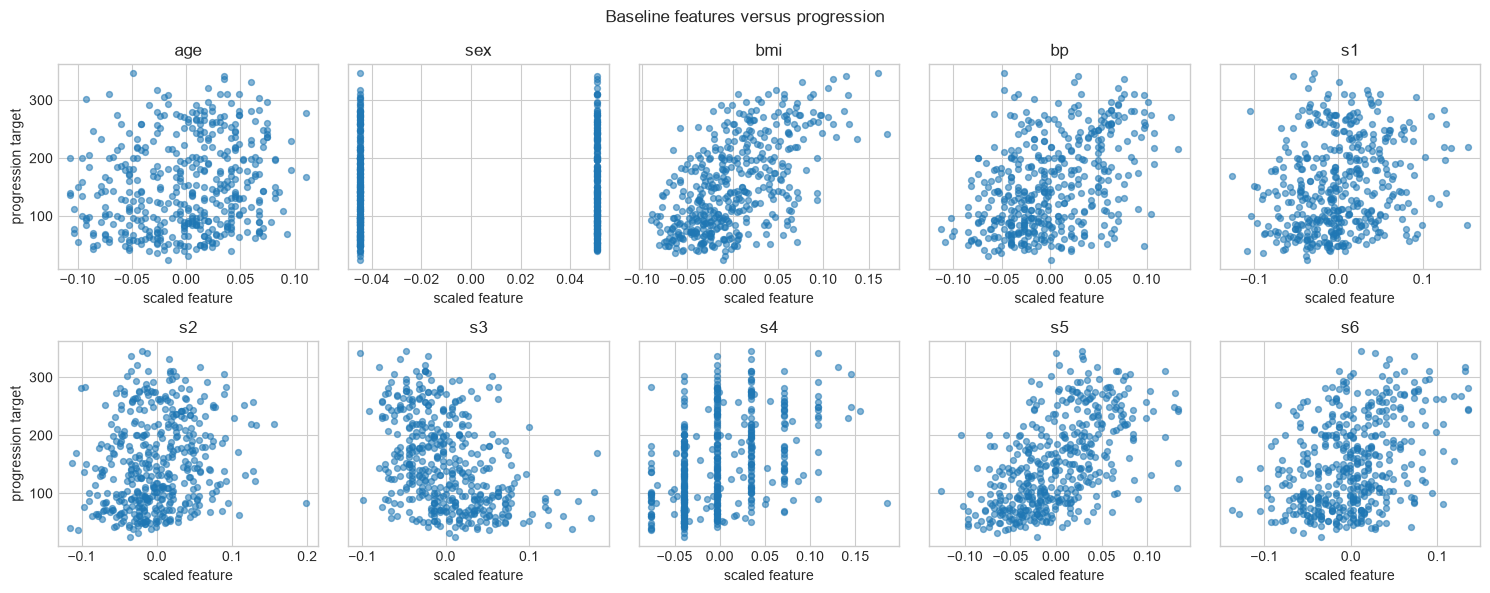

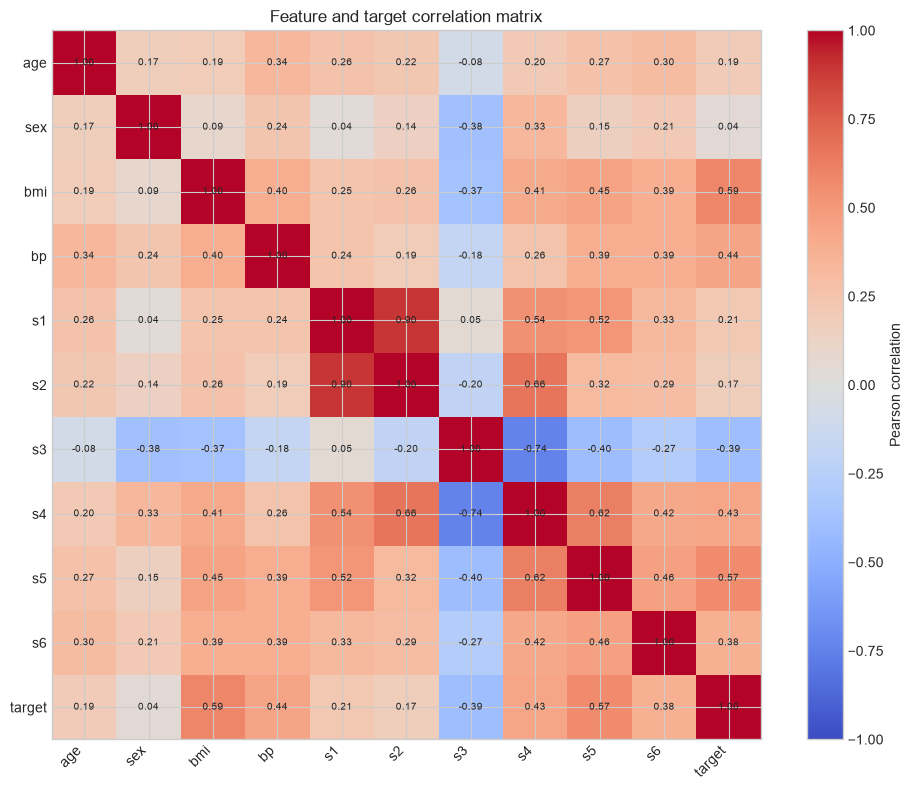

,correlation with target
bmi,0.586
s5,0.566
bp,0.441
s4,0.430
s6,0.382
s1,0.212
age,0.188
s2,0.174
sex,0.043
s3,-0.395


In [3]:
feature_columns = [column for column in data.columns if column != TARGET]
data[feature_columns + [TARGET]].hist(figsize=(14, 10), bins=24, layout=(4, 3), edgecolor='white')
plt.suptitle('Distributions of baseline features and one-year progression', y=1.01)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(15, 6), sharey=True)
for axis, feature in zip(axes.flat, feature_columns):
    axis.scatter(data[feature], data[TARGET], alpha=0.55, s=18)
    axis.set(title=feature, xlabel='scaled feature')
axes[0, 0].set_ylabel('progression target')
axes[1, 0].set_ylabel('progression target')
fig.suptitle('Baseline features versus progression')
fig.tight_layout()
plt.show()

correlations = data.corr(numeric_only=True)
fig, axis = plt.subplots(figsize=(10, 8))
image = axis.imshow(correlations, cmap='coolwarm', vmin=-1, vmax=1)
axis.set_xticks(range(len(correlations)), correlations.columns, rotation=45, ha='right')
axis.set_yticks(range(len(correlations)), correlations.columns)
for row in range(len(correlations)):
    for column in range(len(correlations)):
        axis.text(column, row, f'{correlations.iloc[row, column]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(image, ax=axis, label='Pearson correlation')
axis.set_title('Feature and target correlation matrix')
fig.tight_layout()
plt.show()

display(correlations[TARGET].drop(TARGET).sort_values(ascending=False).rename('correlation with target').to_frame())

**EDA observations.** All ten predictors are numerical and standardized, so no categorical encoding is required. The scatter plots are noisy and mostly show modest marginal trends; BMI is useful but does not explain all variation in progression. The correlation matrix helps identify correlated predictors (notably related serum measurements), which can make polynomial coefficients unstable even when predictions are usable. The distributions also show that a small sample can contain extreme target values, so we inspect held-out errors rather than relying only on a single average score.

## 3. Cleaning and data split

The file has no missing values; the bundled data contains no extra identifiers or categorical fields needing cleanup. We retain all observations rather than remove extreme values solely because they are unusual: they may be genuine outcomes and deleting them without domain evidence would change the task. The source features and response are already scaled by scikit-learn. We split before model selection and use the validation partition only for comparisons.

In [4]:
X_train, X_validation, X_test, y_train, y_validation, y_test = split_data(data)
split_sizes = pd.DataFrame({
    'rows': [len(X_train), len(X_validation), len(X_test)],
    'fraction': [len(X_train) / len(data), len(X_validation) / len(data), len(X_test) / len(data)],
}, index=['train', 'validation', 'test'])
display(split_sizes)
assert len(X_train) + len(X_validation) + len(X_test) == len(data)
assert set(X_train.index).isdisjoint(X_validation.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_validation.index).isdisjoint(X_test.index)

,rows,fraction
train,330,0.747
validation,45,0.102
test,67,0.152


## 4. Part 2: univariate BMI polynomial regression

Fit six models, degrees 0 through 5, using only `bmi`. Degree zero is the training-target mean baseline. Each model is fitted on training rows; training and validation R-squared, MAE, and MAPE are shown side by side. We select the lowest validation MAE, while also checking R-squared and the train/validation gap for signs of overfitting.

In [5]:
X_train_bmi = X_train[[BMI]]
X_validation_bmi = X_validation[[BMI]]
X_test_bmi = X_test[[BMI]]
univariate_results, univariate_models = evaluate_regressors(
    make_univariate_models(), X_train_bmi, X_validation_bmi, y_train, y_validation
)
display(univariate_results.round(3))
best_univariate_name = select_best_by_validation_mae(univariate_results)
best_univariate = univariate_models[best_univariate_name]
print(f'Best BMI model by validation MAE: {best_univariate_name}')
print(f'Equation (coefficients rounded to 2 decimals): {polynomial_equation(best_univariate)}')

,Train R-squared,Train MAE,Train MAPE (%),Validation R-squared,Validation MAE,Validation MAPE (%)
Model,,,,,,
BMI polynomial degree 0,0.000,66.548,63.352,-0.000,63.447,58.793
BMI polynomial degree 1,0.354,52.278,48.462,0.449,41.998,40.445
BMI polynomial degree 2,0.355,52.267,48.448,0.449,41.758,40.310
BMI polynomial degree 3,0.355,52.223,48.356,0.447,41.741,40.259
BMI polynomial degree 4,0.358,51.944,47.964,0.449,41.953,40.241
BMI polynomial degree 5,0.359,51.814,47.831,0.454,42.083,40.340


Best BMI model by validation MAE: BMI polynomial degree 3
Equation (coefficients rounded to 2 decimals): progression = 151.28 +1012.43 * bmi^1 +1028.74 * bmi^2 -6158.21 * bmi^3


### Best univariate model: held-out test, fitted parameters, and one prediction

The test metrics below are the final estimate for the degree selected from validation data. In a polynomial regression, `PolynomialFeatures.get_feature_names_out()` exposes the design-matrix terms; the number of fitted regression parameters is one coefficient per generated term plus the intercept. Degree zero instead fits one constant mean. The BMI example prediction uses `0.05` standardized BMI-feature units, not a clinical BMI value.

In [6]:
univariate_test_metrics = test_regression_model(best_univariate, X_test_bmi, y_test)
display(pd.Series(univariate_test_metrics, name='test score').to_frame().round(3))

parameter_rows = []
for name, model in univariate_models.items():
    if name.endswith('degree 0'):
        terms = ['constant mean']
        count = 1
    else:
        polynomial = model.named_steps['polynomialfeatures']
        terms = polynomial.get_feature_names_out([BMI]).tolist()
        count = polynomial_parameter_count(model)
    parameter_rows.append({'model': name, 'features from get_feature_names_out()': ', '.join(terms), 'trainable parameters': count})
display(pd.DataFrame(parameter_rows).set_index('model'))

chosen_bmi_value = 0.05
print(f'Predicted progression at standardized bmi={chosen_bmi_value:.2f}: {bmi_prediction(best_univariate, chosen_bmi_value):.2f}')

,test score
R-squared,0.207
MAE,54.629
MAPE (%),48.541


,features from get_feature_names_out(),trainable parameters
model,,
BMI polynomial degree 0,constant mean,1
BMI polynomial degree 1,bmi,2
BMI polynomial degree 2,"bmi, bmi^2",5
BMI polynomial degree 3,"bmi, bmi^2, bmi^3",10
BMI polynomial degree 4,"bmi, bmi^2, bmi^3, bmi^4",17
BMI polynomial degree 5,"bmi, bmi^2, bmi^3, bmi^4, bmi^5",26


Predicted progression at standardized bmi=0.05: 203.70


### Fit over train, validation, and test observations

This plot uses the same selected model for all three sets. A separate fit to each partition would leak evaluation observations into model fitting and would not represent held-out performance.

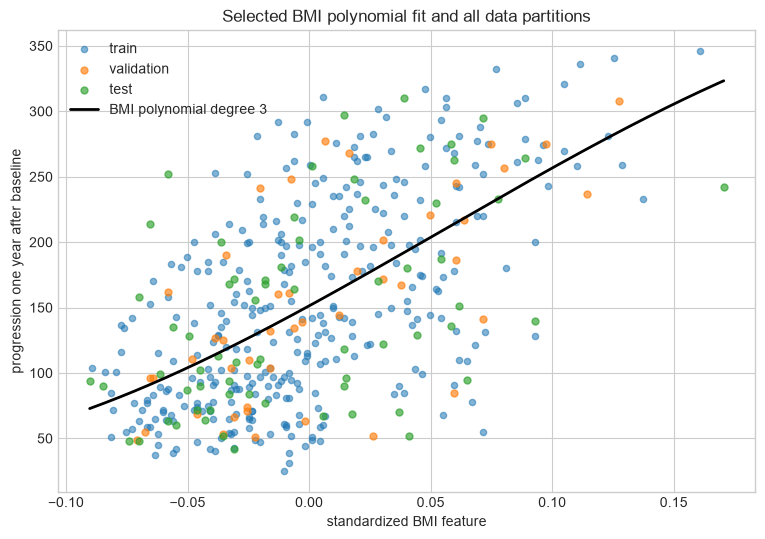

In [7]:
bmi_grid = np.linspace(data[BMI].min(), data[BMI].max(), 300)
grid_predictions = best_univariate.predict(pd.DataFrame({BMI: bmi_grid}))
plt.figure(figsize=(9, 6))
plt.scatter(X_train_bmi[BMI], y_train, alpha=0.55, s=20, label='train')
plt.scatter(X_validation_bmi[BMI], y_validation, alpha=0.65, s=25, label='validation')
plt.scatter(X_test_bmi[BMI], y_test, alpha=0.65, s=25, label='test')
plt.plot(bmi_grid, grid_predictions, color='black', linewidth=2, label=best_univariate_name)
plt.xlabel('standardized BMI feature')
plt.ylabel('progression one year after baseline')
plt.title('Selected BMI polynomial fit and all data partitions')
plt.legend()
plt.show()

## 5. Part 3: multivariate regression models

Using all ten features, compare polynomial regressions of degrees 2 and 3, decision trees with maximum depths 2 and 4, and KNN regressors with 5 and 15 neighbors. KNN uses feature standardization fitted within its pipeline (the original data is already scaled, but this keeps preprocessing attached to the estimator). The polynomial models expand the 10 predictors to 65 degree-1/2 terms or 285 degree-1/2/3 terms, so the degree-3 model has many parameters for only 330 training observations. Regression metrics use the same target scale and validation-based MAE selection.

In [8]:
part3_results, part3_models = evaluate_regressors(
    make_multivariate_models(), X_train, X_validation, y_train, y_validation
)
display(part3_results.round(3))
best_part3_name = select_best_by_validation_mae(part3_results)
best_part3_model = part3_models[best_part3_name]
print(f'Best Part 3 regression by validation MAE: {best_part3_name}')
part3_test_metrics = test_regression_model(best_part3_model, X_test, y_test)
display(pd.Series(part3_test_metrics, name='Part 3 selected model: test').to_frame().round(3))

parameter_summary = pd.DataFrame({
    name: describe_parameterization(model) for name, model in part3_models.items()
}, index=['fitted parameterization']).T
display(parameter_summary)

,Train R-squared,Train MAE,Train MAPE (%),Validation R-squared,Validation MAE,Validation MAPE (%)
Model,,,,,,
Multivariate polynomial degree 2,0.598,39.697,34.939,0.603,37.745,41.098
Multivariate polynomial degree 3,0.891,18.596,17.156,-125.339,333.915,191.917
Decision tree max_depth=2,0.443,47.730,42.300,0.462,41.216,39.652
Decision tree max_depth=4,0.608,39.553,34.444,0.255,47.000,48.025
kNN k=5,0.578,39.886,34.457,0.426,45.529,45.999
kNN k=15,0.489,44.509,39.289,0.553,40.188,41.171


Best Part 3 regression by validation MAE: Multivariate polynomial degree 2


,Part 3 selected model: test
R-squared,0.337
MAE,45.867
MAPE (%),39.474


,fitted parameterization
Multivariate polynomial degree 2,4226 coefficients incl. intercept
Multivariate polynomial degree 3,81226 coefficients incl. intercept
Decision tree max_depth=2,4 leaf values; split rules are not coefficients
Decision tree max_depth=4,16 leaf values; split rules are not coefficients
kNN k=5,No fitted coefficients; stores training examples
kNN k=15,No fitted coefficients; stores training examples


## 6. Part 3: logistic regression classifiers

For a distinct binary risk-screening exercise, define `high progression` as target values at or above the **training-set median**; apply that same cutoff to validation and test. Compare two regularization strengths (`C=0.1` and `C=1.0`) by validation F1, then report accuracy, precision, recall, F1, and ROC-AUC. A false negative means a high-progression case is missed; a false positive means a lower-progression case is flagged. Which error is more costly depends on the intended screening workflow, so accuracy alone is not sufficient. This cutoff and model are educational only, not validated for patient care.

In [9]:
logistic_results, logistic_models, high_progression_cutoff = evaluate_logistic_models(
    make_logistic_models(), X_train, X_validation, y_train, y_validation
)
display(logistic_results.round(3))
best_logistic_name = str(logistic_results['Validation F1'].idxmax())
best_logistic = logistic_models[best_logistic_name]
logistic_test_metrics = test_logistic_model(best_logistic, X_test, y_test, high_progression_cutoff)
print(f'Training median threshold: {high_progression_cutoff:.1f}')
print(f'Best classifier by validation F1: {best_logistic_name}')
display(pd.Series(logistic_test_metrics, name='logistic test score').to_frame().round(3))
y_test_high = (y_test >= high_progression_cutoff).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test_high, best_logistic.predict(X_test), labels=[0, 1]).ravel()
print(f'Test confusion counts: TN={tn}, FP={fp}, FN={fn}, TP={tp}')
logistic_estimator = best_logistic.named_steps['logisticregression']
print(f'Logistic regression fitted coefficients: {logistic_estimator.coef_.size + logistic_estimator.intercept_.size} (10 weights + intercept)')

,Train Accuracy,Train Precision,Train Recall,Train F1,Train ROC-AUC,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation ROC-AUC
Model,,,,,,,,,,
Logistic regression C=0.1,0.736,0.737,0.741,0.739,0.836,0.844,0.826,0.864,0.844,0.927
Logistic regression C=1.0,0.727,0.729,0.729,0.729,0.839,0.822,0.792,0.864,0.826,0.927


Training median threshold: 142.0
Best classifier by validation F1: Logistic regression C=0.1


,logistic test score
Accuracy,0.731
Precision,0.688
Recall,0.733
F1,0.710
ROC-AUC,0.827


Test confusion counts: TN=27, FP=10, FN=8, TP=22
Logistic regression fitted coefficients: 11 (10 weights + intercept)


## 7. Error analysis and conclusions

Metrics summarize average behavior but hide individual misses. Examine the largest absolute errors for the selected univariate model and its residual pattern. The test rows shown here are diagnostic examples, not a basis for further tuning.

,actual,predicted,residual,absolute_error,standardized_bmi
78,252.0,97.27,154.73,154.73,-0.06
56,52.0,194.32,-142.32,142.32,0.04
113,297.0,165.92,131.08,131.08,0.01
104,95.0,219.67,-124.67,124.67,0.06
218,214.0,91.12,122.88,122.88,-0.07
211,70.0,189.73,-119.73,119.73,0.04
9,310.0,192.03,117.97,117.97,0.04
407,140.0,249.33,-109.33,109.33,0.09


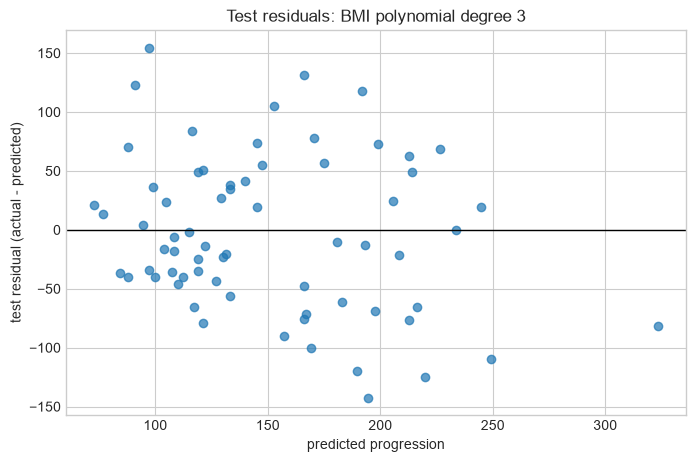

Selected univariate model: BMI polynomial degree 3
Test R-squared=0.207, MAE=54.63, MAPE=48.5%
Selected multivariate Part 3 model: Multivariate polynomial degree 2
Part 3 test R-squared=0.337, MAE=45.87, MAPE=39.5%


In [10]:
test_predictions = best_univariate.predict(X_test_bmi)
test_error_table = pd.DataFrame({
    'actual': y_test,
    'predicted': test_predictions,
    'residual': y_test - test_predictions,
    'absolute_error': np.abs(y_test - test_predictions),
    'standardized_bmi': X_test_bmi[BMI],
}).sort_values('absolute_error', ascending=False)
display(test_error_table.head(8).round(2))

plt.figure(figsize=(8, 5))
plt.scatter(test_predictions, y_test - test_predictions, alpha=0.7)
plt.axhline(0, color='black', linewidth=1)
plt.xlabel('predicted progression')
plt.ylabel('test residual (actual - predicted)')
plt.title(f'Test residuals: {best_univariate_name}')
plt.show()

print(f"Selected univariate model: {best_univariate_name}")
print(f"Test R-squared={univariate_test_metrics['R-squared']:.3f}, MAE={univariate_test_metrics['MAE']:.2f}, MAPE={univariate_test_metrics['MAPE (%)']:.1f}%")
print(f"Selected multivariate Part 3 model: {best_part3_name}")
print(f"Part 3 test R-squared={part3_test_metrics['R-squared']:.3f}, MAE={part3_test_metrics['MAE']:.2f}, MAPE={part3_test_metrics['MAPE (%)']:.1f}%")

### Conclusions and limitations

- Use the validation tables and untouched test results to describe the selected model's performance. A substantial train/validation gap indicates overfitting; a modest R-squared or broad residual spread indicates that baseline features leave much of the outcome unexplained. The largest-error table shows cases for which the BMI-only model's estimate is least reliable.
- BMI alone is an intentionally simple screening signal. It cannot represent the joint contribution of age, blood pressure, serum measurements, interactions, or unobserved factors. Polynomial curves can extrapolate implausibly outside the observed feature range.
- The multivariate degree-3 expansion has 285 predictor terms plus an intercept, high relative to this dataset's sample size; the model is prone to overfitting and unstable coefficients. Trees can miss smooth trends, while KNN predictions depend on the chosen neighborhood size and local sample density. Validation-based selection reduces, but does not eliminate, selection optimism.
- MAPE can overemphasize small true values and is not always suitable for targets near zero. R-squared can be negative on held-out samples. MAE is in the dataset's progression units, not a probability or clinical severity score.
- Logistic regression answers a different, thresholded classification question. Precision/recall and the confusion matrix expose the false-positive/false-negative tradeoff emphasized in classification and screening; changing the cutoff or class threshold changes that tradeoff. Its scores must not be compared directly with the regression metrics.
- This dataset has only 442 observations, comes from a bundled teaching dataset, and contains scaled values rather than a deployable clinical data pipeline. There is no external validation, calibration or subgroup analysis here. These models must not be used to diagnose, reassure, or make treatment decisions; clinical use would require representative data, governance, prospective validation, and clinician oversight.